# 004 两层神经网络：题目要求

**需要完成：** 手写 affine→ReLU→affine→Softmax 前后向；通过固定输出、损失和梯度检查；完成玩具数据拟合与 CIFAR-10 训练；分析曲线、调整超参数并测试最佳模型。

**实验范围与验收：** 原题目标为验证和测试准确率超过 48%；超过 52% 为进一步挑战。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：两层 ReLU 网络

第一层学习像素组合，ReLU 只放行正激活，第二层组合隐藏特征得到类别得分。去掉非线性，两次仿射变换仍等价于一次仿射变换。

![两层 ReLU 网络的数据流](../assets/model_flow/004_TwoLayerNet.svg)

**从定义推到实现。**

$$
Z=XW_1+b_1,\quad A=\max(0,Z),\quad S=AW_2+b_2
$$

令 G 为交叉熵对 S 的导数。第二层权重梯度为 AᵀG；隐藏层收到 GW₂ᵀ，再逐元素乘 Z>0 的掩码。第一层权重梯度为 Xᵀ 乘这一结果。偏置在 batch 中共享，故沿样本轴求和。

**库在这里解决什么问题？** NumPy 的 maximum、dot 和布尔索引分别负责激活、仿射变换和反向掩码；Solver 在本题由模型自己的 train 方法承担。

| 本题导入的模块 | 在这份实验中的用途 |
|---|---|
| `cs231n.classifiers.neural_net` | 加载当前作业的本地实现。模型代码负责计算预测或损失，notebook 用真实输入检查和训练。 |
| `cs231n.data_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `cs231n.gradient_check` | 用中心差分近似导数，独立核对手写反向传播。 |
| `cs231n.vis_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `matplotlib.pyplot` | 把像素、损失或准确率转换为可读图像，绘图单元只读取已有结果。 |
| `numpy` | 把一批样本作为数组处理。矩阵乘法合并样本计算，广播让偏置或均值沿样本轴复用。 |
| `os` | 读取运行环境或处理路径，连接实验代码和本机文件系统。 |
| `pathlib` | 构造数据与结果的文件路径，使当前作业从约定目录读取资源。 |
| `random` | 控制 Python 自己的随机抽样，例如图像平移。它与 NumPy、PyTorch 的随机状态分别管理。 |
| `study_runtime` | 解析共享数据路径、读取本机资源或保存本题结果，避免各题重复创建数据副本。 |
| `sys` | 设置本作业的模块搜索路径，使同名 cs231n 包来自当前 assignment。 |
| `threadpoolctl` | 限制数值库的并行线程，避免小矩阵运算把更多时间花在线程调度上。 |

**用一个小例子检查理解。** 取 N=5、D=4、H=10、C=3，第一层输出 5×10，第二层输出 5×3。若某个隐藏激活为零，它对本样本的反向梯度被屏蔽；其他样本仍可更新同一个权重。

# 实现一个神经网络
在这个练习中，我们将开发一个具有全连接层的神经网络来执行分类，并在CIFAR-10数据集上进行测试。

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备网络与误差检查**

导入手写 TwoLayerNet 与绘图库，设置相对误差函数。该模型为 affine→ReLU→affine，训练时再计算 Softmax 损失；反向传播由 NumPy 显式实现，不依赖自动求导。

此处定义 `rel_error(x, y)`。函数体在调用时执行。

本块实际导入：`numpy`、`matplotlib.pyplot`、`cs231n.classifiers.neural_net.TwoLayerNet`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`rel_error` → 第 6 块。

In [2]:
# 有点布局

import numpy as np
import matplotlib.pyplot as plt

from cs231n.classifiers.neural_net import TwoLayerNet

%matplotlib inline
plt.rcParams['figure.figsize'] = (12.0, 9.0) # 设置地块的默认大小
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# 用于自动重新装入外部模块
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """逐元素计算 |x−y| / max(1e−8, |x|+|y|)，返回其中最大值。分母很小时还应查看绝对误差。"""
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

我们将在文件`s231n/classifiers/neural_net`中使用类`TwoLayerNet`。表示我们的网络实例。网络参数存储在实例变量`self`中。其中键是字符串参数名，值是numpy数组。

**第 3 块｜构造可核对的小数据**

固定随机种子，构造输入维度 4、隐藏维度 10、类别数 3 的小网络及五个样本。小规模确定性输入使得每一项输出都可与参考值比较，便于在真实训练前定位前向和反向错误。

此处定义 `init_toy_model()`。函数体在调用时执行。

此处定义 `init_toy_data()`。函数体在调用时执行。

本块产出的变量接着用于：`X` → 第 4 块，`init_toy_model` → 第 7 块，`net` → 第 4 块，`y` → 第 5 块。

In [3]:
# 创建一个小网和一些玩具数据来检查您的执行 。
# 请注意,我们设置了可重复实验的随机种子.

input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
  np.random.seed(0)
  return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
  np.random.seed(1)
  X = 10 * np.random.randn(num_inputs, input_size)
  y = np.array([0, 1, 2, 2, 1])
  return X, y

net = init_toy_model()
X, y = init_toy_data()

# 向前传播:计算分数
打开文件`cs231n/classifiers/neural_net`看看`TwoLayerNet.loss`方法。这个函数与您为SVM和Softmax练习编写的损失函数非常相似:它获取数据和权重，并计算类分数、损失和参数上的梯度。实现前向传播的第一部分，它使用权重和偏差来计算所有输入的分数。

**第 4 块｜检查无标签前向**

调用 net.loss(X) 而不传标签，得到 (5,3) 类别得分。与预置正确矩阵逐项比较，检查权重形状、偏置广播和 ReLU 的位置；这个检查尚不涉及 Softmax 或参数更新。

前序输入：`net` 来自第 3 块，`X` 来自第 3 块。

In [4]:
scores = net.loss(X)
print ('Your scores:')
print (scores)
print
print ('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print (correct_scores)
print

# 差别应该很小,我们得到的只有< 1e-7
print ('Difference between your scores and correct scores:')
print (np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]
correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]
Difference between your scores and correct scores:
3.6802720745909845e-08


# 前向传播:计算损失
在同一个函数中，实现数据计算的第二部分和正则化损耗。

**第 5 块｜核对含正则项的损失**

传入标签和 reg=0.1，计算平均交叉熵加 0.5·reg·ΣW²，并与参考标量比较。系数 0.5 对应梯度中的 reg·W，损失与梯度必须采用一致约定。

前序输入：`net` 来自第 3 块，`X` 来自第 3 块，`y` 来自第 3 块。

In [5]:
loss, _ = net.loss(X, y, reg=0.1)
correct_loss = 1.30378789133

# 应该是很小的,我们得到< 1e-12
print ('Difference between your loss and correct loss:')
print (np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.794120407794253e-13


# 后向传播
实现函数的其余部分。这将计算关于变量“W1”、“b1”、“W2”和“b2”的损失梯度。现在你(希望!)有一个正确实现的前向传播，你可以调试你的后向传播使用一个数字梯度检查:

**第 6 块｜逐参数检查梯度**

逐一扰动 W1、b1、W2、b2，计算中心差分梯度并与解析梯度比较。反向链条从类别误差经过第二层权重，再用 ReLU 掩码阻断非正激活位置，最后传播到第一层参数。

本块实际导入：`cs231n.gradient_check.eval_numerical_gradient`。各模块在本题中的职责见开头的库说明。

前序输入：`net` 来自第 3 块，`X` 来自第 3 块，`y` 来自第 3 块，`rel_error` 来自第 2 块。

In [6]:
from cs231n.gradient_check import eval_numerical_gradient

# 使用数字梯度检查来检查您对后方通行证的执行情况 。
# 如果您的执行正确,则数字与
# W1,W2,b1,和b2中每个分析梯度应小于1e-8.

loss, grads = net.loss(X, y, reg=0.1)

# 均应小于1e-8左右
for param_name in grads:
  f = lambda W: net.loss(X, y, reg=0.1)[0]
  param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
  print ('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447625e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738421e-09


# 训练网络
为了训练网络，我们将使用随机梯度下降法(SGD)，类似于SVM和Softmax分类器。看看`TwoLayerNet.train`函数。训练并填写缺失的部分，以执行训练程序。这应该与SVM和Softmax分类器的训练过程非常相似。您还必须实现`TwoLayerNet.predict`，即在网络训练过程中，训练过程会周期性地进行预测，以跟踪一段时间内的准确性。
一旦你实现了这个方法，运行下面的代码在玩具数据上训练一个两层网络。你的训练损失应该小于0.2。

**第 7 块｜测试小数据能否拟合**

在同一小数据集上执行 100 次 SGD 更新，同时把该数据用作验证，以检查网络能否记住简单样本。输出最终损失和曲线；小样本拟合成功只是训练回路检查，不代表泛化能力。

前序输入：`init_toy_model` 来自第 3 块，`X` 来自第 3 块，`y` 来自第 3 块。

Final training loss: 

 0.017149607938732093


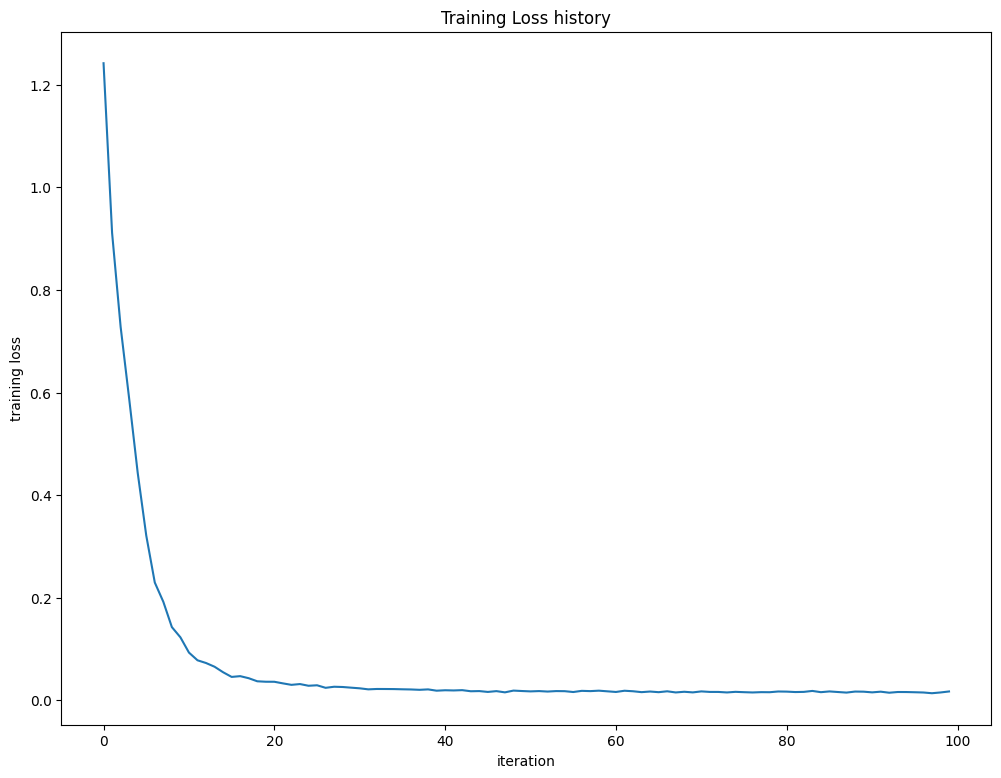

In [7]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=1e-5,
            num_iters=100, verbose=False)

print ('Final training loss: ', stats['loss_history'][-1])

# 绘制损失历史
plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# 加载数据
现在您已经实现了一个两层的网络，它可以通过渐变检查并处理玩具数据，现在是时候加载我们最喜欢的CIFAR-10数据了，这样我们就可以使用它来训练真实数据集上的分类器。

**第 8 块｜读取真实分类数据**

读取并划分 CIFAR-10，将图像展平并减去训练集均值，返回训练、验证和测试特征。两层网络已有独立偏置参数，因此这里不需要像线性分类器那样追加常数列。

此处定义 `get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000)`。函数体在调用时执行。

- `X_train.reshape(num_training, -1)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

本块实际导入：`cs231n.data_utils.load_CIFAR10`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`X_test` → 第 14 块，`X_train` → 第 9 块，`X_val` → 第 9 块，`y_test` → 第 14 块，`y_train` → 第 9 块。

In [8]:
from cs231n.data_utils import load_CIFAR10

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    """读取 CIFAR-10 后按参数截取训练、验证、测试集合，再使用训练集统计量处理另外两组。返回的图像数组与标签数组按同一行号对应。"""
    # 装入原始 CIFAR- 10 数据
    cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'
    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)
        
    # 分解数据
    mask = range(num_training, num_training + num_validation)
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = range(num_training)
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = range(num_test)
    X_test = X_test[mask]
    y_test = y_test[mask]

    # 使数据正常化:减去平均图像
    mean_image = np.mean(X_train, axis=0)
    X_train -= mean_image  # 训练图的每一行都减去同一训练均值；这里只改变内存中的特征，不修改原始数据文件。
    X_val -= mean_image  # 验证样本必须使用训练阶段估计的均值，否则预处理会使用验证数据自身的信息。
    X_test -= mean_image

    # 将数据重排为行
    X_train = X_train.reshape(num_training, -1)
    X_val = X_val.reshape(num_validation, -1)
    X_test = X_test.reshape(num_test, -1)

    return X_train, y_train, X_val, y_val, X_test, y_test


# 启动上述功能以获取我们的数据。
X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()
print ('Train data shape: ', X_train.shape)
print ('Train labels shape: ', y_train.shape)
print ('Validation data shape: ', X_val.shape)
print ('Validation labels shape: ', y_val.shape)
print ('Test data shape: ', X_test.shape)
print ('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 3072)
Train labels shape:  (49000,)
Validation data shape:  (1000, 3072)
Validation labels shape:  (1000,)
Test data shape:  (1000, 3072)
Test labels shape:  (1000,)


# 训练网络
训练我们的网络，我们将使用带动量的SGD。此外，随着优化的进行，我们将采用指数学习速率计划来调整学习速率;在每个epoch之后，我们将通过将其乘以衰减率来降低学习率。

**第 9 块｜建立训练起点**

先使用较小隐藏层和初始学习率训练网络，记录损失、训练准确率和验证准确率。该实验是诊断起点，验证表现不佳时需结合损失下降速度与训练验证差距分析原因。

- `net.predict(X_val)`：使用已训练的模型计算预测标签。

前序输入：`X_train` 来自第 8 块，`y_train` 来自第 8 块，`X_val` 来自第 8 块，`y_val` 来自第 8 块。

本块产出的变量接着用于：`input_size` → 第 12 块，`net` → 第 11 块，`num_classes` → 第 12 块，`stats` → 第 10 块。

In [9]:
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)

# 训练网络
stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=1000, batch_size=200,
            learning_rate=1e-3, learning_rate_decay=0.95,
            reg=0.5, verbose=True)

# 关于审定集的预测
val_acc = (net.predict(X_val) == y_val).mean()
print ('Validation accuracy: ', val_acc)

iteration 0 / 1000: loss 2.302954


iteration 100 / 1000: loss 1.964946


iteration 200 / 1000: loss 1.750511


iteration 300 / 1000: loss 1.613416


iteration 400 / 1000: loss 1.714102


iteration 500 / 1000: loss 1.546602


iteration 600 / 1000: loss 1.644443


iteration 700 / 1000: loss 1.448247


iteration 800 / 1000: loss 1.456147


iteration 900 / 1000: loss 1.506688


Validation accuracy:  0.465


# 调试训练
使用上面提供的默认参数，验证集的验证精度应该在0.29左右。这不是很好。
了解问题所在的一种策略是，在优化期间绘制损失函数和训练集和验证集的准确性。
另一种策略是将在网络的第一层学到的权重可视化。在大多数以视觉数据为训练对象的神经网络中，第一层的权值在可视化时通常会显示一些可见的结构。

**第 10 块｜比较损失与准确率轨迹**

把上一训练的损失与准确率历史画在同一图中。损失下降缓慢且训练验证均低可能表示欠拟合；训练持续上升而验证停滞则提示过拟合，不能单凭一条曲线下结论。

前序输入：`stats` 来自第 9 块。

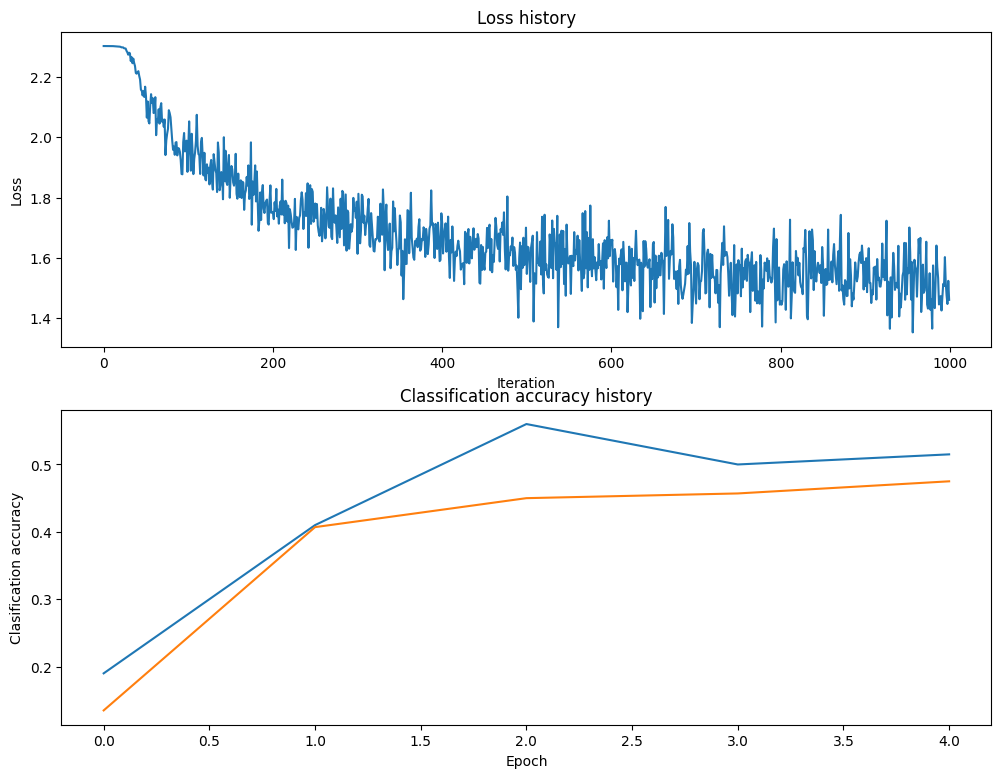

In [10]:
# 绘制损失函数和列车/验证权限
plt.subplot(2, 1, 1)
plt.plot(stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(stats['train_acc_history'], label='train')
plt.plot(stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Clasification accuracy')
plt.show()

**第 11 块｜查看第一层模板**

把第一层 W1 的每个隐藏单元重排为 32×32×3 图像，排列为网格。显示的滤波模板用于检查学习是否产生结构，同时也可能暴露过大的权重或无明显更新。

此处定义 `show_net_weights(net)`。函数体在调用时执行。

- `W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)`：调整轴的顺序，使下一算子的通道、空间或矩阵维度对齐。

- `W1.reshape(32, 32, 3, -1)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

本块实际导入：`cs231n.vis_utils.visualize_grid`。各模块在本题中的职责见开头的库说明。

前序输入：`net` 来自第 9 块。

本块产出的变量接着用于：`show_net_weights` → 第 13 块。

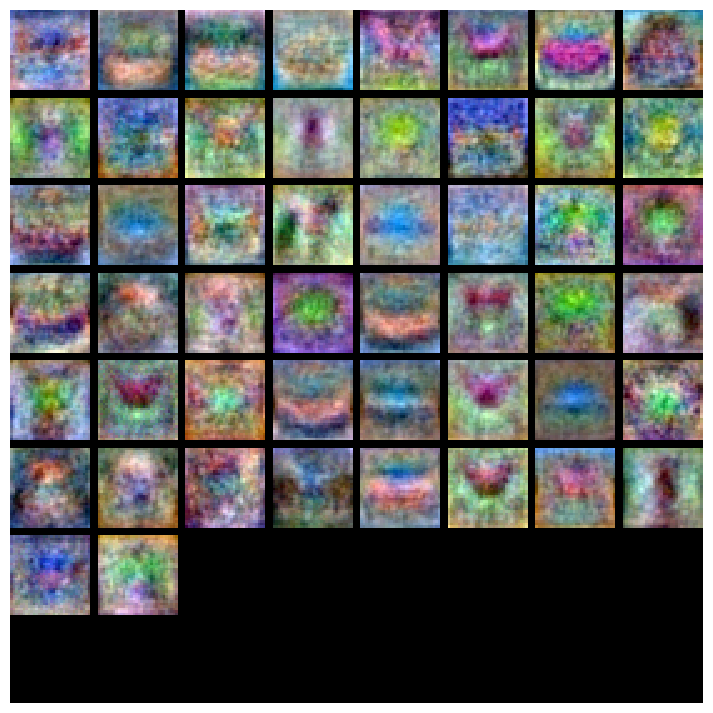

In [11]:
from cs231n.vis_utils import visualize_grid

# 可视化网络的重量

def show_net_weights(net):
  W1 = net.params['W1']
  W1 = W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)
  plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
  plt.gca().axis('off')
  plt.show()

show_net_weights(net)

# 调整你的超参数
**怎么了?** 看看上面的可视化，我们可以看到损失或多或少呈线性下降，这似乎表明学习率可能太低了。此外，训练的准确性和验证的准确性之间没有差距，这说明我们使用的模型容量较低，我们应该增加模型的大小。另一方面，对于一个非常大的模型，我们期望看到更多的过拟合，这将表现为训练和验证准确性之间的一个非常大的差距。

**调优** 调整超参数并开发它们如何影响最终性能的直觉是使用神经网络的一个重要部分，因此我们希望您进行大量实践。下面，您应该试验各种超参数的不同值，包括隐层大小、学习率、训练周期数和正则化强度。您也可以考虑调优学习速率衰减，但是您应该能够使用默认值获得良好的性能。

**近似的结果** 您的目标应该是在验证集上获得超过48%的分类准确率。我们最好的网络在验证集上获得超过52%的准确率。

**实验** 你的目标是在CIFAR-10上获得尽可能好的结果，使用一个全连接的神经网络。对于每一个超过52%的测试集，我们将奖励你一个额外的积分。您可以自由地实现自己的技术(例如，使用PCA来降低维度，或添加dropout，或向求解器添加特性，等等)。

**第 12 块｜用验证集选择隐藏层网络**

保留原来的两层结构，按指定学习率、正则强度、400 个隐藏单元和 2000 次更新进行训练。对每组配置记录训练/验证准确率，并仅按验证集选择 best_net；原实现使用 SGD，不能把说明中的动量误写为实际执行的优化器。

- `net.predict(X_train)`：使用已训练的模型计算预测标签。

前序输入：`input_size` 来自第 9 块，`num_classes` 来自第 9 块，`X_train` 来自第 8 块，`y_train` 来自第 8 块，`X_val` 来自第 8 块，`y_val` 来自第 8 块。

本块产出的变量接着用于：`best_net` → 第 13 块。

In [12]:
best_net = None # 将最佳模型存储到此中
#learning_rates = [1e-3, 1.2e-3, 1.4e-3, 1.6e-3, 1.8e-3]
#regularization_strengths = [1e-4, 1e-3, 1e-2]
learning_rates = [1.6e-3]
regularization_strengths = [1e-2]
hidden_size = 400
results = {}
best_val = -1
for rate in learning_rates:
    for reg in regularization_strengths:
        net = TwoLayerNet(input_size, hidden_size, num_classes)
        stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=2000, batch_size=400,
            learning_rate=rate, learning_rate_decay=0.9,
            reg=reg, verbose=True)        
        y_train_pred = net.predict(X_train)
        acc_tr = np.mean(y_train == y_train_pred)
        y_val_pred = net.predict(X_val)
        acc_val = np.mean(y_val == y_val_pred)
        
        results[(rate, reg)] = (acc_tr, acc_val)
        if acc_val > best_val:
            best_val = acc_val
            best_net = net
            
for rate, reg in sorted(results):
    train_accuracy, val_accuracy = results[(rate, reg)]
    print ('rate %e reg %e train accuracy: %f val accuracy: %f' % (
                rate, reg, train_accuracy, val_accuracy))
    
print ('best validation accuracy achieved during cross-validation: %f' % best_val)
#################################################################################

iteration 0 / 2000: loss 2.302612


iteration 100 / 2000: loss 1.821605


iteration 200 / 2000: loss 1.656478


iteration 300 / 2000: loss 1.485311


iteration 400 / 2000: loss 1.555701


iteration 500 / 2000: loss 1.449879


... (11 outputs left out)

iteration 1700 / 2000: loss 1.117758


iteration 1800 / 2000: loss 1.114176


iteration 1900 / 2000: loss 1.130866


rate 1.600000e-03 reg 1.000000e-02 train accuracy: 0.641286 val accuracy: 0.552000
best validation accuracy achieved during cross-validation: 0.552000


**第 13 块｜查看最佳网络的模板**

将已选最佳模型的第一层权重可视化，与初始小网络的模板作定性比较。可视化使用训练后参数，但不能代替独立验证指标。

前序输入：`show_net_weights` 来自第 11 块，`best_net` 来自第 12 块。

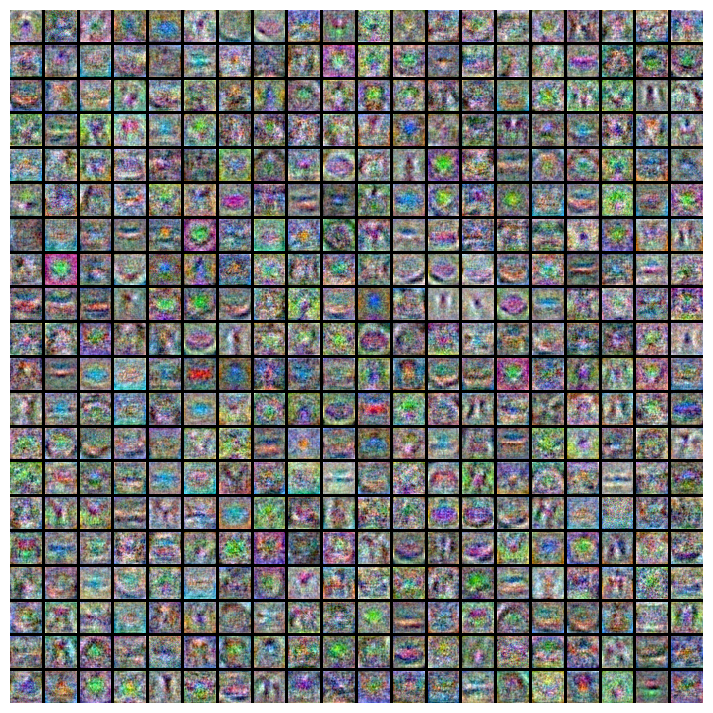

In [13]:
# 直观最佳网络的重量
show_net_weights(best_net)

## 在测试集上运行
当你完成实验时，你应该在测试集上评估你最终的训练网络;你应该得到48%以上。

**我们会给你额外的分数，每1%的准确性高于52%.**

**第 14 块｜评估独立测试集**

使用 best_net 在保留测试集上预测并报告准确率，随后保存模型参数和训练记录。判断是否达到题目要求应同时查看验证和测试结果，并注明本题使用的测试子集规模。

- `best_net.predict(X_test)`：使用已训练的模型计算预测标签。

前序输入：`best_net` 来自第 12 块，`X_test` 来自第 8 块，`y_test` 来自第 8 块。

In [14]:
test_acc = (best_net.predict(X_test) == y_test).mean()
print ('Test accuracy: ', test_acc)

Test accuracy:  0.54


### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**第 15 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [15]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '004_TwoLayerNet')


本机实验指标： {'best_val': 0.552, 'test_acc': 0.54, 'val_acc': 0.465, 'acc_tr': 0.6412857142857142, 'acc_val': 0.552}


## 实践补充：问题、检查与方法选择

**实际核对。** 原说明提到动量，但训练函数实际执行普通 SGD；本次解析按实际代码说明。数值稳定处理与 Softmax 同步修复。

**结果解释。** 验证 55.2%、测试 54.0%，满足本题 48% 目标。隐藏层扩大并不保证继续提高验证准确率，应结合训练验证差距判断。

**方法选择。** 保留手写前后向的教学目的。框架式实现已在 PyTorch 作业中独立训练，这里不重复添加一个只改变代码包装的网络。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。